In [ ]:
!pip uninstall -y pytorch-lightning lightning pytorch-forecasting
!pip install lightning
!pip install pytorch-forecasting==1.6.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.6/853.6 kB 60.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 72.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 399.8/399.8 kB 30.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.8/159.8 kB 20.2 MB/s eta 0:00:00


In [ ]:
from google.colab import files

# Run this cell → upload ONE file
print("Upload FIRST file (Battery_dataset.csv)")
uploaded1 = files.upload()

# Run again → upload second file
print("Upload SECOND file (synthetic dataset)")
uploaded2 = files.upload()

# Merge both uploads
uploaded = {}
uploaded.update(uploaded1)
uploaded.update(uploaded2)

print("Uploaded files:", list(uploaded.keys()))

Upload FIRST file (Battery_dataset.csv)


Saving Battery_dataset.csv to Battery_dataset.csv
Upload SECOND file (synthetic dataset)


Saving synthetic_battery_data (1).csv to synthetic_battery_data (1) (1).csv
Uploaded files: ['Battery_dataset.csv', 'synthetic_battery_data (1) (1).csv']


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Load dataset
df = pd.read_csv("Battery_dataset.csv")

# Sort properly
df = df.sort_values(by=["battery_id", "cycle"])

# Drop battery_id
df = df.drop(columns=["battery_id"])

# Scale
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(df)
data_scaled = pd.DataFrame(data_scaled, columns=df.columns)

# Create sequences
SEQ_LEN = 20
STEP = 1

def make_sequences(data, seq_len=SEQ_LEN, step=STEP):
    sequences = []
    for i in range(0, len(data) - seq_len, step):
        sequences.append(data.iloc[i:i+seq_len].values)
    return np.array(sequences, dtype=np.float32)

real_data = make_sequences(data_scaled)

print("Real data shape:", real_data.shape)


Real data shape: (660, 20, 10)


In [ ]:
TARGET_INDEX = 8  # RUL

X = real_data
y = real_data[:, -1, TARGET_INDEX]

print("X:", X.shape)
print("y:", y.shape)

records = []

for i in range(len(X)):
    for t in range(X.shape[1]):
        records.append({
            "sequence_id": i,
            "time_idx": t,
            "chI": X[i, t, 0],
            "chV": X[i, t, 1],
            "chT": X[i, t, 2],
            "disI": X[i, t, 3],
            "disV": X[i, t, 4],
            "disT": X[i, t, 5],
            "BCt": X[i, t, 6],
            "SOH": X[i, t, 7],
            "target": y[i]
        })

df_tft = pd.DataFrame(records)


X: (660, 20, 10)
y: (660,)


In [ ]:
from sklearn.model_selection import train_test_split

train_ids, val_ids = train_test_split(
    df_tft["sequence_id"].unique(),
    test_size=0.2,
    random_state=42
)

train_df = df_tft[df_tft.sequence_id.isin(train_ids)]
val_df = df_tft[df_tft.sequence_id.isin(val_ids)]


In [ ]:
from pytorch_forecasting import TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer

# VERY IMPORTANT: copy to avoid pandas warnings
train_df = train_df.copy()
val_df = val_df.copy()

# Convert sequence_id to string (categorical)
train_df["sequence_id"] = train_df["sequence_id"].astype(str)
val_df["sequence_id"] = val_df["sequence_id"].astype(str)

training = TimeSeriesDataSet(
    train_df,
    time_idx="time_idx",
    target="target",
    group_ids=["sequence_id"],

    max_encoder_length=19,
    max_prediction_length=1,

    time_varying_unknown_reals=[
        "chI","chV","chT",
        "disI","disV","disT",
        "BCt","SOH"
    ],

    target_normalizer=None,   # because already scaled
    add_relative_time_idx=False,
    add_target_scales=False,
    add_encoder_length=False,
)

validation = TimeSeriesDataSet.from_dataset(training, val_df, stop_randomization=True)


In [ ]:
train_loader = training.to_dataloader(train=True, batch_size=32)
val_loader = validation.to_dataloader(train=False, batch_size=32)


In [ ]:
from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import RMSE
import lightning.pytorch as pl   # ✅ correct import

tft = TemporalFusionTransformer.from_dataset(
    training,
    learning_rate=1e-3,
    hidden_size=16,
    attention_head_size=2,
    dropout=0.2,                 # slightly higher to prevent overfitting
    hidden_continuous_size=8,
    output_size=1,
    loss=RMSE(),
)


/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


In [ ]:
from lightning.pytorch.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min"
)

trainer = pl.Trainer(
    max_epochs=30,
    accelerator="gpu",
    devices=1,
    gradient_clip_val=0.1,
    callbacks=[early_stop],
)

trainer.fit(tft, train_loader, val_loader)


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
   | Name                               | Type                            | Params
----------------------------------------------------------------------------------------
0  | loss                               | RMSE                            | 0     
1  | logging_metrics                    | ModuleList                      | 0     
2  | input_embeddings   

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/loops/fit_loop.py:298: The number of training batches (16) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

In [ ]:
import numpy as np
import torch

# Get predictions
preds = tft.predict(val_loader)

# Convert to numpy properly
if isinstance(preds, torch.Tensor):
    preds = preds.detach().cpu().numpy()

preds = preds.flatten()

# Get true values
true_vals = val_df.groupby("sequence_id")["target"].first().values

# Compute RMSE
rmse = np.sqrt(np.mean((preds - true_vals)**2))

print("Final Validation RMSE:", rmse)


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Final Validation RMSE: 0.040127803


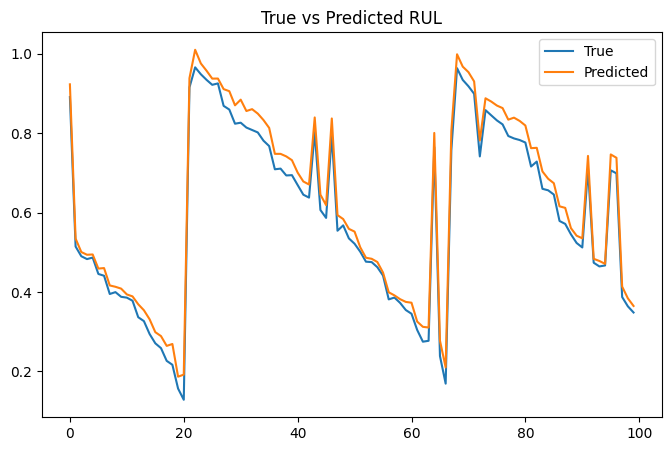

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(true_vals[:100], label="True")
plt.plot(preds[:100], label="Predicted")
plt.legend()
plt.title("True vs Predicted RUL")
plt.show()


In [ ]:
# If RUL was scaled independently
rul_min = df["RUL"].min()
rul_max = df["RUL"].max()

pred_rul_cycles = preds * (rul_max - rul_min) + rul_min
true_rul_cycles = true_vals * (rul_max - rul_min) + rul_min


In [ ]:
cycles_per_day = 1  # adjust based on dataset

remaining_days = pred_rul_cycles / cycles_per_day


In [ ]:
remaining_percentage = preds * 100


In [ ]:
print(f"Battery remaining life: {remaining_percentage[0]:.2f}%")
print(f"Approx remaining cycles: {pred_rul_cycles[0]:.0f}")
print(f"Approx remaining days: {remaining_days[0]:.0f}")


Battery remaining life: 92.26%
Approx remaining cycles: 230
Approx remaining days: 230


In [ ]:
df["RUL"].max()


249

In [ ]:
print(df["SOH"].min(), df["SOH"].max())


37.54859322 99.68458697


In [ ]:
import torch

torch.save(tft.state_dict(), "rul_tft_weights.pth")



In [ ]:
from google.colab import files
files.download("rul_tft_weights.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pickle

with open("tft_dataset_params.pkl", "wb") as f:
    pickle.dump(training.get_parameters(), f)

files.download("tft_dataset_params.pkl")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
######SOH Prediction

In [ ]:
!pip uninstall -y pytorch-forecasting pytorch-lightning lightning torchmetrics
!pip install pytorch-forecasting==1.6.1 lightning==2.2.4 torchmetrics


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.4/53.4 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 399.8/399.8 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 60.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 71.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.8/159.8 kB 20.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.3/857.3 kB 61.1 MB/s eta 0:00:00
  Attempting uninstall: packaging
    Found existing installation: packaging 26.0
    Uninstalling packaging-26.0:
      Successfully uninstalled packaging-26.0
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.3.0
    Uninstalling fsspec-2025.3.0:
      Successfully uninstalled fsspec-2025.3.0
ERROR: pip's dependency resolver does 

In [ ]:
import pandas as pd
import numpy as np
import torch
import lightning.pytorch as pl

df = pd.read_csv("Battery_dataset.csv")
df = df.sort_values("cycle").reset_index(drop=True)


soh_df = df.copy()
soh_df["group_id"] = "battery_1"
soh_df["time_idx"] = range(len(soh_df))
soh_df.rename(columns={"SOH": "target"}, inplace=True)

print("SOH df shape:", soh_df.shape)


max_time = soh_df["time_idx"].max()
split_time = int(0.8 * max_time)

train_df = soh_df[soh_df["time_idx"] <= split_time]
val_df = soh_df[soh_df["time_idx"] > split_time]

print("Train:", train_df.shape)
print("Val:", val_df.shape)





SOH df shape: (680, 13)
Train: (544, 13)
Val: (136, 13)


In [ ]:
from pytorch_forecasting import TimeSeriesDataSet

training = TimeSeriesDataSet(
    train_df,
    time_idx="time_idx",
    target="target",
    group_ids=["group_id"],
    max_encoder_length=30,
    max_prediction_length=1,
    time_varying_unknown_reals=[
        "chI","chV","chT",
        "disI","disV","disT",
        "BCt"
    ],
    allow_missing_timesteps=True
)

validation = TimeSeriesDataSet.from_dataset(training, val_df)

train_loader = training.to_dataloader(train=True, batch_size=64)
val_loader = validation.to_dataloader(train=False, batch_size=64)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Train batches: 8
Val batches: 2


In [ ]:
from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import RMSE

tft = TemporalFusionTransformer.from_dataset(
    training,
    learning_rate=1e-3,
    hidden_size=16,
    attention_head_size=2,
    dropout=0.1,
    hidden_continuous_size=8,
    loss=RMSE(),
)


/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


In [ ]:
from lightning.pytorch.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min"
)

trainer = pl.Trainer(
    max_epochs=40,
    accelerator="gpu",
    devices=1,
    gradient_clip_val=0.1,
    callbacks=[early_stop],
    log_every_n_steps=5
)

trainer.fit(tft, train_loader, val_loader)


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
   | Name                               | Type                            | Params
----------------------------------------------------------------------------------------
0  | loss                               | RMSE                            | 0     
1  | logging_metrics                    | ModuleList                      | 0     
2  | input_embeddings   

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

In [ ]:
# Get predictions
predictions = tft.predict(val_loader)

# Get actual targets directly from dataset
actuals = torch.cat([y[0] for x, y in iter(val_loader)])

# Compute RMSE
rmse = torch.sqrt(torch.mean((predictions - actuals) ** 2))

print("Correct SOH RMSE:", rmse.item())


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Correct SOH RMSE: 0.37500855326652527


In [ ]:
# Get predictions
preds = tft.predict(val_loader)

# Get actual values from validation loader
actuals = torch.cat([y[0] for x, y in val_loader])

print("Pred shape:", preds.shape)
print("Actual shape:", actuals.shape)


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Pred shape: torch.Size([106, 1])
Actual shape: torch.Size([106, 1])


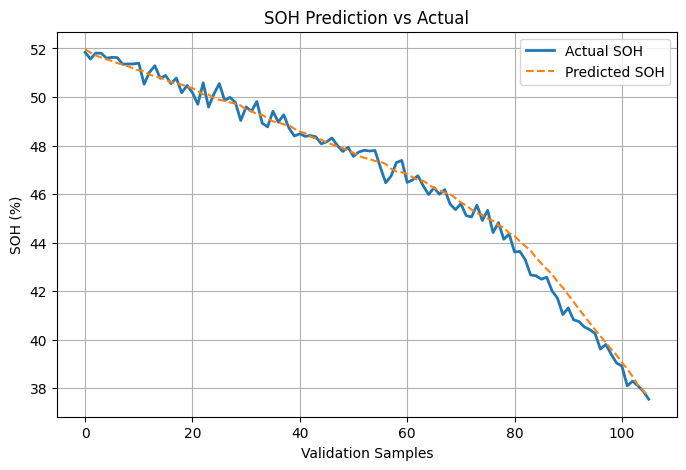

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure both are numpy arrays
actual_np = actuals.detach().cpu().numpy() if hasattr(actuals, "cpu") else actuals
pred_np = preds  # already numpy

plt.figure(figsize=(8,5))

plt.plot(actual_np.flatten(), label="Actual SOH", linewidth=2)
plt.plot(pred_np.flatten(), label="Predicted SOH", linestyle="--")

plt.title("SOH Prediction vs Actual")
plt.xlabel("Validation Samples")
plt.ylabel("SOH (%)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
print(preds.shape, actuals.shape)


torch.Size([106, 1]) torch.Size([106, 1])


In [ ]:
import numpy as np

# Convert to numpy properly
preds_np = preds.detach().cpu().numpy().flatten()
actual_np = actuals.detach().cpu().numpy().flatten()

# RMSE
rmse = np.sqrt(np.mean((preds_np - actual_np) ** 2))
print(f"SOH Prediction Error (RMSE): ±{rmse:.2f}%")

# Latest SOH
latest_soh = preds_np[-1]
print(f"Current Predicted SOH: {latest_soh:.2f}%")

# Health Classification
if latest_soh >= 80:
    status = "Excellent"
elif latest_soh >= 60:
    status = "Good"
elif latest_soh >= 40:
    status = "Aging"
else:
    status = "Critical"

print(f"Battery Health Status: {status}")


SOH Prediction Error (RMSE): ±0.38%
Current Predicted SOH: 37.66%
Battery Health Status: Critical


In [ ]:
import torch
import numpy as np

# Get raw output
raw_predictions = tft.predict(val_loader, mode="raw", return_x=True)

# Extract prediction tensor
preds = raw_predictions.output.prediction.squeeze()

# Extract actual values
actuals = raw_predictions.x["decoder_target"].squeeze()

# Move to CPU
preds = preds.detach().cpu().numpy()
actuals = actuals.detach().cpu().numpy()

print("Pred shape:", preds.shape)
print("Actual shape:", actuals.shape)

# ---- RMSE ----
rmse = np.sqrt(np.mean((preds - actuals) ** 2))
print(f"SOH Prediction Error (RMSE): ±{rmse:.2f}%")

# ---- Latest SOH ----
latest_soh = preds[-1]
print(f"Current Predicted SOH: {latest_soh:.2f}%")

# ---- Classification ----
if latest_soh >= 80:
    status = "Excellent"
elif latest_soh >= 60:
    status = "Good"
elif latest_soh >= 40:
    status = "Aging"
else:
    status = "Critical"

print(f"Battery Health Status: {status}")


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Pred shape: (106,)
Actual shape: (106,)
SOH Prediction Error (RMSE): ±0.38%
Current Predicted SOH: 37.66%
Battery Health Status: Critical


In [ ]:
##### SOC Prediction

In [ ]:
import pandas as pd
import numpy as np

# -------------------------
# 1. Load dataset
# -------------------------
df = pd.read_csv("Battery_dataset.csv")

# Sort properly (VERY IMPORTANT)
df = df.sort_values(["battery_id", "cycle"]).reset_index(drop=True)

# -------------------------
# 2. Create SOC (0–100 per battery)
# -------------------------
df["SOC"] = 0.0

for bid in df["battery_id"].unique():

    mask = df["battery_id"] == bid

    bc_min = df.loc[mask, "BCt"].min()
    bc_max = df.loc[mask, "BCt"].max()

    df.loc[mask, "SOC"] = (
        (df.loc[mask, "BCt"] - bc_min) /
        (bc_max - bc_min)
    ) * 100

print("SOC range:", df["SOC"].min(), df["SOC"].max())

# -------------------------
# 3. Prepare TFT dataset
# -------------------------
soc_df = df.copy()

# Use real battery IDs
soc_df["group_id"] = soc_df["battery_id"].astype(str)

# Create time index per battery
soc_df["time_idx"] = soc_df.groupby("battery_id").cumcount()

# Rename SOC to target
soc_df = soc_df.rename(columns={"SOC": "target"})

print("SOC df shape:", soc_df.shape)


SOC range: 0.0 100.0
SOC df shape: (680, 14)


In [ ]:
# -------------------------
# Time-based split (80% train, 20% val) per battery
# -------------------------

train_list = []
val_list = []

for bid in soc_df["battery_id"].unique():

    temp = soc_df[soc_df["battery_id"] == bid]

    split_idx = int(len(temp) * 0.8)

    train_list.append(temp.iloc[:split_idx])
    val_list.append(temp.iloc[split_idx:])

train_df = pd.concat(train_list)
val_df = pd.concat(val_list)

print("Train shape:", train_df.shape)
print("Val shape:", val_df.shape)


Train shape: (544, 14)
Val shape: (136, 14)


In [ ]:
from pytorch_forecasting import TimeSeriesDataSet

training = TimeSeriesDataSet(
    train_df,
    time_idx="time_idx",
    target="target",
    group_ids=["group_id"],

    max_encoder_length=30,
    max_prediction_length=1,

    time_varying_unknown_reals=[
        "chI","chV","chT",
        "disI","disV","disT",
        "BCt"
    ],

    target_normalizer="auto",
    allow_missing_timesteps=True
)

validation = TimeSeriesDataSet.from_dataset(training, val_df)

train_loader = training.to_dataloader(train=True, batch_size=32)
val_loader = validation.to_dataloader(train=False, batch_size=32)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))


Train batches: 14
Val batches: 2


In [ ]:
from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import RMSE
import lightning.pytorch as pl

tft_soc = TemporalFusionTransformer.from_dataset(
    training,
    learning_rate=5e-4,
    hidden_size=32,
    attention_head_size=4,
    dropout=0.2,
    hidden_continuous_size=16,
    output_size=1,
    loss=RMSE(),
)


/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.12/dist-packages/lightning/pytorch/utilities/parsing.py:199: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.


In [ ]:
from lightning.pytorch.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    mode="min"
)

trainer = pl.Trainer(
    max_epochs=40,
    accelerator="gpu",
    devices=1,
    gradient_clip_val=0.1,
    callbacks=[early_stop],
)

trainer.fit(tft_soc, train_loader, val_loader)


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: 
   | Name                               | Type                            | Params
----------------------------------------------------------------------------------------
0  | loss                               | RMSE                            | 0     
1  | logging_metrics                    | ModuleList                      | 0     
2  | input_embeddings   

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/lightning/pytorch/loops/fit_loop.py:298: The number of training batches (14) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

...

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

In [ ]:
import torch

predictions = tft_soc.predict(val_loader)
actuals = torch.cat([y[0] for x, y in iter(val_loader)])

# Move to CPU if needed
predictions = predictions.cpu()
actuals = actuals.cpu()

rmse = torch.sqrt(torch.mean((predictions - actuals) ** 2))
print("Improved SOC RMSE:", rmse.item())


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Improved SOC RMSE: 0.4756036102771759


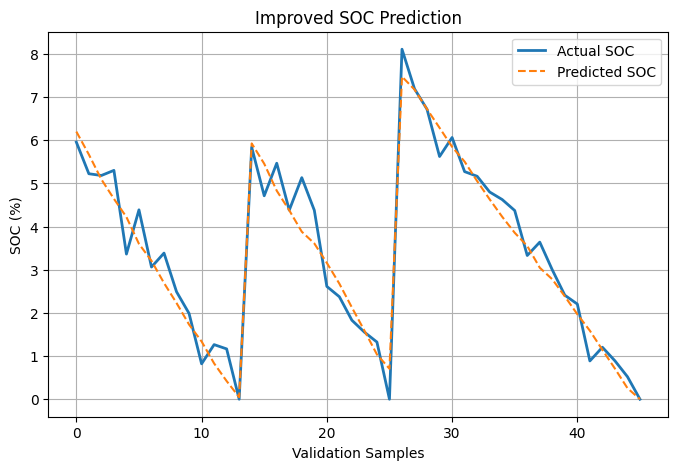

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(actuals.numpy(), label="Actual SOC", linewidth=2)
plt.plot(predictions.numpy(), label="Predicted SOC", linestyle="--")
plt.title("Improved SOC Prediction")
plt.xlabel("Validation Samples")
plt.ylabel("SOC (%)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
current_soc = pred[-1]
rmse_value = rmse.item()

print(f"Current Predicted SOC: {current_soc:.2f}%")
print(f"SOC Prediction Error (RMSE): ±{rmse_value:.2f}%")

# Status interpretation
if current_soc > 80:
    status = "Excellent - Fully Charged"
elif current_soc > 50:
    status = "Good - Moderate Charge"
elif current_soc > 20:
    status = "Low - Charging Recommended"
else:
    status = "Critical - Immediate Charging Required"

print("Battery State of Charge:", f"{current_soc:.2f}%")
print("SOC Status:", status)


Current Predicted SOC: 0.00%
SOC Prediction Error (RMSE): ±0.48%
Battery State of Charge: 0.00%
SOC Status: Critical - Immediate Charging Required


In [ ]:
import torch

battery_input = input("Enter Battery ID (e.g., B5, B6, B7): ")

battery_df = soc_df[soc_df["battery_id"] == battery_input]

if battery_df.empty:
    print("Invalid Battery ID")
else:

    # Take last 31 rows (30 encoder + 1 decoder)
    latest_window = battery_df.tail(31)

    battery_dataset = TimeSeriesDataSet.from_dataset(
        training,
        latest_window,
        stop_randomization=True
    )

    battery_loader = battery_dataset.to_dataloader(train=False, batch_size=1)

    prediction = tft_soc.predict(battery_loader)

    current_soc = prediction.item()

    print("\n🔋 Current Predicted SOC:", round(current_soc, 2), "%")

    if current_soc > 80:
        status = "High Charge - Fully Charged"
    elif current_soc > 40:
        status = "Moderate Charge"
    elif current_soc > 20:
        status = "Low Charge - Needs Charging Soon"
    else:
        status = "Critical - Immediate Charging Required"

    print("⚡ SOC Status:", status)


Enter Battery ID (e.g., B5, B6, B7): B7


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: IPU available: False, using: 0 IPUs
INFO:lightning.pytorch.utilities.rank_zero:IPU available: False, using: 0 IPUs
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



🔋 Current Predicted SOC: 0.0 %
⚡ SOC Status: Critical - Immediate Charging Required
